In [ ]:
import pandas as pd
from zoneinfo import ZoneInfo
from datetime import datetime as dt, timezone, timedelta
import holidays
import seaborn as sns
import json
import meteostat as ms
import numpy as np

### Import station data
Map each station's 'shortname' to their important features

In [ ]:
stations_df = pd.read_csv('All_Data/Station_Info/citibike-stations.csv')
id_to_shortname = dict(zip(stations_df['station_id'], stations_df['short_name']))
id_to_lat = dict(zip(stations_df['station_id'], stations_df['lat']))
id_to_lon = dict(zip(stations_df['station_id'], stations_df['lon']))
id_to_name = dict(zip(stations_df['station_id'], stations_df['name']))
shortname_to_name = dict(zip(stations_df['short_name'], stations_df['name']))

In [ ]:
stations_df.head()

,capacity,eightd_has_key_dispenser,electric_bike_surcharge_waiver,external_id,has_kiosk,lat,lon,name,region_id,rental_methods,rental_url,short_name,station_id
0,66,True,False,66db5fae-0aca-11e7-82f6-3863bb44ef7c,True,40.764397,-73.973715,Grand Army Plaza & Central Park S,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,6839.1,281
1,33,True,False,66db6da2-0aca-11e7-82f6-3863bb44ef7c,True,40.704633,-74.013617,Broadway & Battery Pl,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,4962.01,304
2,64,False,False,66dbc982-0aca-11e7-82f6-3863bb44ef7c,True,40.755103,-73.974987,E 47 St & Park Ave,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,6584.12,359
3,45,False,False,66dbe441-0aca-11e7-82f6-3863bb44ef7c,True,40.722438,-74.005664,6 Ave & Canal St,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,5500.07,377
4,36,False,False,66dbe601-0aca-11e7-82f6-3863bb44ef7c,True,40.734927,-73.992005,University Pl & E 14 St,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,5905.11,382


# Exploratory Data Analysis


**Load the cleaned dataset:**

- 'valset_dense_few_stations' has all the data collected for just a few bike stations. This detailed data creates better vizualzations
- Unfortuantly I don't have enough RAM to load all the available data for all stations for training
 

In [ ]:
df_viz = process_file('All_Data/Cleaned/few_2019_dense.parquet')


Before dropping NA: 1088066 rows
After dropping NA: 1087037 rows


In [ ]:
print("Loaded stations : ")

stations_viz = list(df_viz['shortname'].unique())

for station in stations_viz:
    print(shortname_to_name[station], ': ', station)

Loaded stations : 
Park Pl & Church St :  5288.08
Mercer St & Spring St :  5532.01
South St & Whitehall St :  4846.01
Centre St & Worth St :  5279.03
W 13 St & 7 Ave :  6030.04
Broadway & Battery Pl :  4962.01
Clinton St & Grand St :  5303.06
Centre St & Chambers St :  5207.01
E 7 St & Avenue A :  5626.07


### Visualizations of Typical Daily Cycles

**Mercer St & Spring St** is located near NYU and SOHO in the central city.
- Below is graphed 4/7 to 4/13 a full week from Sunday to Saturday
- The upward and downward cyclic trend during the weekdays in very clear, however there is significant variation between how far cycles rise and dip limiting the accuracy of a potential model
- Weekends show high station capacities but very pretty unpredicable variation

Mercer St & Spring St :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

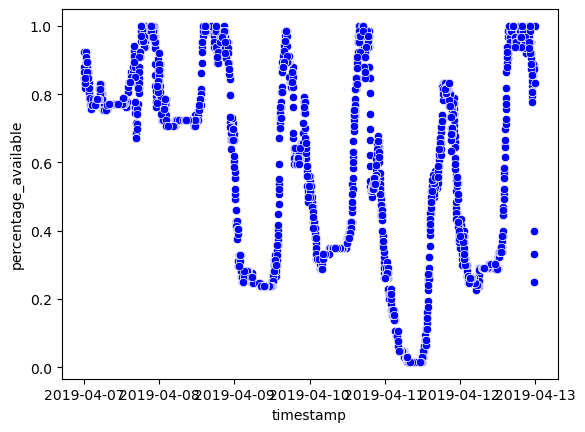

In [ ]:
SHORTNAME = '5532.01'

timeframe_graphed = (df_viz['timestamp'] >= dt(2019,4,7, tzinfo = timezone.utc)) & (df_viz['timestamp'] < dt(2019,4, 13, tzinfo = timezone.utc))
print(shortname_to_name[SHORTNAME], ':')

sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')

**Single Cycle (Weekday)**
- Not sure about the uptick at the afternoon, but it seems to happen every day, maybe some event at the station specifically?

Mercer St & Spring St :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

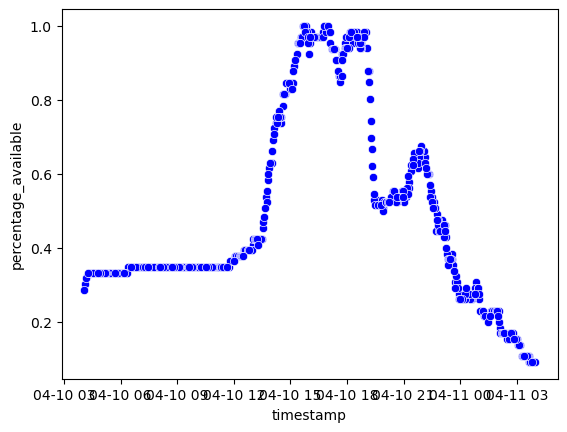

In [ ]:
SHORTNAME = '5532.01'

timeframe_graphed = (df_viz['timestamp'] >= dt(2019,4,10, tzinfo = ZoneInfo("America/New_York"))) & (df_viz['timestamp'] < dt(2019,4, 11, tzinfo = ZoneInfo("America/New_York")))
print(shortname_to_name[SHORTNAME], ':')

sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')

**E 7 St & Avenue A** is located in East Village in a residential center.
- The same week is graphed 4/7 to 4/13
- The similar predictable cyclic trend is visible on the weekdays with weekends have more variation.
- Alignment of cyclic is the opposite to inner city stations from commuter behaviour
- Stations is severe in lacking bikes or docks when needed


E 7 St & Avenue A :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

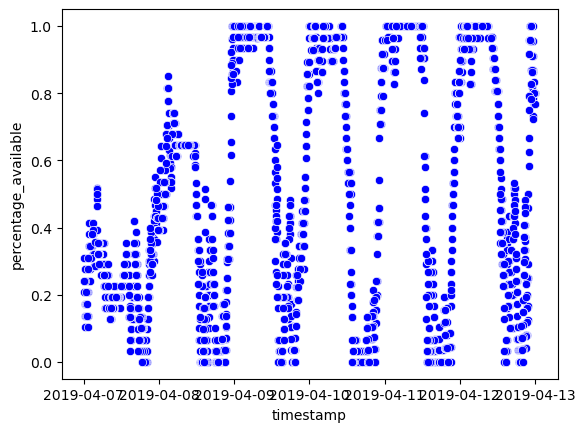

In [ ]:
SHORTNAME = '5626.07'

timeframe_graphed = (df_viz['timestamp'] >= dt(2019,4,7, tzinfo = timezone.utc)) & (df_viz['timestamp'] < dt(2019,4, 13, tzinfo = timezone.utc))
print(shortname_to_name[SHORTNAME], ':')

sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')

**Daily Cycle** 
- opposite for a commuter bike station as expected

E 7 St & Avenue A :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

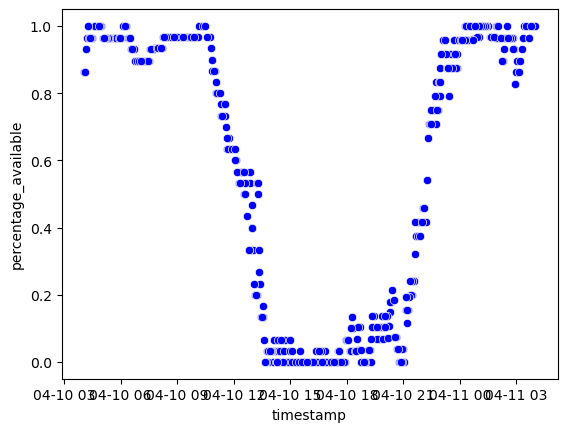

In [ ]:
SHORTNAME = '5626.07'

timeframe_graphed = (df_viz['timestamp'] >= dt(2019,4,10, tzinfo = ZoneInfo("America/New_York"))) & (df_viz['timestamp'] < dt(2019,4, 11, tzinfo = ZoneInfo("America/New_York")))
print(shortname_to_name[SHORTNAME], ':')

sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')

### Some more Capacity Data
-  Percentage of time each stations had no docs or no bikes

In [ ]:
df_viz['station_name'] = df_viz['shortname'].map(shortname_to_name)

nobikes_perc = df_viz.groupby('station_name')['percentage_available'].apply(lambda x: round((x == 0).mean() * 100, 2))
noracks_perc = df_viz.groupby('station_name')['percentage_available'].apply(lambda x: round((x == 1).mean() * 100, 2))

nobikes_perc = nobikes_perc.sort_values()
noracks_perc = noracks_perc.sort_values()

print("--------------")
print("Percentage of time with no bike available: ")
print("--------------")
print(nobikes_perc)
print("--------------")

print("Percentage of time with no docks available: ")
print("--------------")
print(noracks_perc)
print("--------------")

/tmp/ipykernel_11691/84476664.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  nobikes_perc = df_viz.groupby('station_name')['percentage_available'].apply(lambda x: round((x == 0).mean() * 100, 2))
/tmp/ipykernel_11691/84476664.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  noracks_perc = df_viz.groupby('station_name')['percentage_available'].apply(lambda x: round((x == 1).mean() * 100, 2))


--------------
Percentage of time with no bike available: 
--------------
station_name
South St & Whitehall St    4.53
Canal St & Rutgers St      4.54
Broadway & Battery Pl      4.70
W 13 St & 7 Ave            4.94
Clinton St & Grand St      6.71
Centre St & Chambers St    7.03
Mercer St & Spring St      7.05
E 7 St & Avenue A          7.46
Centre St & Worth St       7.95
Park Pl & Church St        8.98
Name: percentage_available, dtype: float64
--------------
Percentage of time with no docks available: 
--------------
station_name
Broadway & Battery Pl       1.05
Centre St & Worth St        2.71
Centre St & Chambers St     2.89
W 13 St & 7 Ave             2.96
South St & Whitehall St     4.21
Canal St & Rutgers St       4.34
Park Pl & Church St         4.70
E 7 St & Avenue A           6.13
Mercer St & Spring St       6.55
Clinton St & Grand St      11.38
Name: percentage_available, dtype: float64
--------------
